# Notebook 00 — Data Audit & Shared Dataset Construction
**Purpose:** Reproducibility anchor, leakage check, outcome definition, and walk-forward split.

**Hypothesis (stated before looking at results):**
Both CSVs share the same feature schema. The 4-year file (base/ML) covers Jan 2022 – Sep 2026; the 5-year rule-based file is a filtered subset of trades from the same instrument and period. No post-entry feature leaks entry-known information.

**Threats to validity:** single instrument (XAUUSD), MetaTrader backtest bias, broker spread assumptions, concurrent positions (trades overlap in time, so they are **not** independent observations).

**Invariants enforced below (fail-fast — asserted, not merely printed):**
1. Every column in `FEATURE_COLS` is known at entry; an assertion fails if a post-entry column sneaks in.
2. Lag features (`prev_R_*`, `streak_*`) are verified empirically to use only trades already **closed** at entry.
3. Unresolved trades (`exit_reason == 'OPEN'` or missing `result_R`) are removed before any statistic is computed.
4. Trades whose outcome resolves inside the next split are purged, so no train label leaks into val/holdout.
5. The saved feature list drops all-NaN and zero-variance columns.

In [4]:
import hashlib, json, sys, warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')


# ── SEEDS & CONSTANTS ───────────────────────────────────────────────────────
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Walk-forward split boundaries — END OF DAY, so a trade entered at any time on
# 2025-05-31 still belongs to train, and the holdout starts 2025-12-01 00:00.
TRAIN_END = pd.Timestamp('2025-05-31 23:59:59')
VAL_END   = pd.Timestamp('2025-11-30 23:59:59')
# Holdout = Dec 2025 → Sep 2026  (~10 months, never touched during tuning)

# MT5 exports timestamps as YYYY.MM.DD HH:MM:SS — always parse with the explicit
# format: inference is locale/version dependent and fails silently to NaT.
DT_FMT   = '%Y.%m.%d %H:%M:%S'
DATE_FMT = '%Y.%m.%d'


def resolve_data_dir() -> Path:
    """DATA/ lives next to notebooks/ — resolve it from the notebook dir or repo root."""
    for candidate in (Path.cwd() / 'DATA', Path.cwd().parent / 'DATA'):
        if candidate.is_dir():
            return candidate.resolve()
    raise FileNotFoundError('DATA/ directory not found in cwd or its parent')


DATA_DIR = resolve_data_dir()
F4 = DATA_DIR / 'PSS_SCALP_XAUUSDm...mss h4 buy and sell,4 years.csv'
F5 = DATA_DIR / 'PSS_SCALP_XAUUSDm...5 years rule based.csv'
for _path in (F4, F5):
    if not _path.is_file():
        raise FileNotFoundError(f'Missing dataset: {_path}')

print(f'RANDOM_SEED : {RANDOM_SEED}')
print(f'TRAIN_END   : {TRAIN_END.date()}')
print(f'VAL_END     : {VAL_END.date()}')
print(f'DATA_DIR    : {DATA_DIR}')
print(f'pandas {pd.__version__} | numpy {np.__version__} | python {sys.version.split()[0]}')

RANDOM_SEED : 42
TRAIN_END   : 2025-05-31
VAL_END     : 2025-11-30
DATA_DIR    : C:\Users\user\Desktop\kairex-test-1\DATA
pandas 3.1.1 | numpy 2.5.4 | python 3.15.2


## 1. Load & Hash Datasets
Raw files are hashed (SHA-256) before anything else, so every downstream artefact maps back to an exact input.
Timestamps are parsed with an explicit format (`%Y.%m.%d %H:%M:%S`) and unresolved trades are dropped at load time.

In [5]:
def file_sha256(path: Path, chunk_size: int = 1 << 16) -> str:
    """SHA-256 of a file, streamed so large exports stay cheap."""
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for chunk in iter(lambda: fh.read(chunk_size), b''):
            h.update(chunk)
    return h.hexdigest()


hash4 = file_sha256(F4)
hash5 = file_sha256(F5)
print(f'4-year CSV SHA-256: {hash4}')
print(f'5-year CSV SHA-256: {hash5}')

# Written now, completed with output hashes in §8
manifest = {
    'created_utc' : datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'random_seed' : RANDOM_SEED,
    'train_end'   : str(TRAIN_END.date()),
    'val_end'     : str(VAL_END.date()),
    'python'      : sys.version.split()[0],
    'pandas'      : pd.__version__,
    'numpy'       : np.__version__,
    'source_files': {F4.name: hash4, F5.name: hash5},
    'hash_4yr'    : hash4,      # kept for backwards compatibility
    'hash_5yr'    : hash5,
}

manifest_path = DATA_DIR / 'run_manifest.json'
with open(manifest_path, 'w', encoding='utf-8') as mf:
    json.dump(manifest, mf, indent=2)
print(f'\nManifest saved to {manifest_path}')

4-year CSV SHA-256: 64621afcc31f04a547de961edafad74b6976a9b9bf265544a566953fc7c56013
5-year CSV SHA-256: 36a1170b56b1dc6ba7e35b37bd5d93960bff1c4497863912760ad316f892e633

Manifest saved to C:\Users\user\Desktop\kairex-test-1\DATA\run_manifest.json


In [6]:
def load_csv(path: Path) -> pd.DataFrame:
    """Read one MT5 export: explicit datetime parsing, unresolved trades removed."""
    df = pd.read_csv(path)
    n_raw = len(df)

    df['open_time']  = pd.to_datetime(df['open_time'],  format=DT_FMT,   errors='raise')
    df['close_time'] = pd.to_datetime(df['close_time'], format=DT_FMT,   errors='raise')
    df['date']       = pd.to_datetime(df['date'],       format=DATE_FMT, errors='coerce')

    # An unresolved trade has no outcome — keeping it would silently count it as a loss.
    unresolved = df['exit_reason'].eq('OPEN') | df['result_R'].isna()
    df = df.loc[~unresolved].copy()

    # Stable sort keeps the export's own order for trades opened on the same bar.
    df = df.sort_values('open_time', kind='mergesort').reset_index(drop=True)

    print(f'[{path.name}] {n_raw:,} rows read → {len(df):,} resolved trades '
          f'({int(unresolved.sum()):,} unresolved removed)')
    return df


df4 = load_csv(F4)   # 4-year  → base model + ML training
df5 = load_csv(F5)   # 5-year  → rule-based (also test/eval)

print(f'\n4-year shape: {df4.shape}  |  5-year shape: {df5.shape}')
for _name, _df in (('4-year', df4), ('5-year', df5)):
    _span = (_df['open_time'].max() - _df['open_time'].min()).days
    print(f'{_name} window: {_df["open_time"].min()} → {_df["open_time"].max()}  '
          f'({_span} days ≈ {_span / 365.25:.2f} years)')

[PSS_SCALP_XAUUSDm...mss h4 buy and sell,4 years.csv] 3,045 rows read → 3,045 resolved trades (0 unresolved removed)
[PSS_SCALP_XAUUSDm...5 years rule based.csv] 982 rows read → 982 resolved trades (0 unresolved removed)

4-year shape: (3045, 91)  |  5-year shape: (982, 91)
4-year window: 2022-01-04 15:36:00 → 2026-09-22 19:51:00  (1722 days ≈ 4.71 years)
5-year window: 2022-01-13 01:05:00 → 2026-09-22 19:25:00  (1713 days ≈ 4.69 years)


## 2. Schema Comparison
Both exports must be column-identical (names, count, **order** and dtypes) before they are pooled or merged; anything else means a different EA export template and every downstream join becomes unsafe.

In [7]:
cols4, cols5 = list(df4.columns), list(df5.columns)
print('Columns only in 4-yr :', sorted(set(cols4) - set(cols5)))
print('Columns only in 5-yr :', sorted(set(cols5) - set(cols4)))
print('Shared columns       :', len(set(cols4) & set(cols5)))

assert cols4 == cols5, (
    'Schema mismatch — identical names, count AND order required. '
    f'4-yr only: {sorted(set(cols4) - set(cols5))}; '
    f'5-yr only: {sorted(set(cols5) - set(cols4))}'
)

dtype_mismatch = {c: (str(df4[c].dtype), str(df5[c].dtype))
                  for c in cols4 if df4[c].dtype != df5[c].dtype}
assert not dtype_mismatch, f'dtype mismatch: {dtype_mismatch}'
print('dtype mismatches     :', dtype_mismatch or 'none')
print(f'\n✓ Schema identical — {len(cols4)} columns, same names, order and dtypes')

Columns only in 4-yr : []
Columns only in 5-yr : []
Shared columns       : 91
dtype mismatches     : none

✓ Schema identical — 91 columns, same names, order and dtypes


## 3. Leakage Check
Every feature must be **known at trade entry** (before `close_time`).

* **Post-entry fields** — outcomes/targets only, never features:
  `close_time, close_price, net_profit, result_R, pnl_R, exit_reason, MFE_R, MAE_R, min_to_MFE, min_to_MAE, min_to_1R, min_to_2R, min_to_3R, min_R_after_1R, min_R_after_2R, max_p_b4_sl, max_L_b4_tp, excursion_flag, duration_min`.
* **Entry-known but non-stationary** — absolute price levels and sizing: `entry, sl, tp`. Not look-ahead, but their distribution drifts from gold ≈ 1,800 to ≈ 3,600 across the sample and `src/config.py` excludes them, so they stay out of the model; their scale-free equivalents (`sl_pips, tp_pips, spread_pips, risk_pts, planned_rr`) are kept.
* **Lag features** — `prev_R_1..3, streak_losses, trades_today_before, mins_since_last_entry` encode *other* trades' outcomes. They are only safe if they use trades that had already **closed** at entry, so §3.2 verifies that empirically instead of trusting the export.

In [8]:
POST_ENTRY_COLS = [
    'close_time','close_price','net_profit','result_R','pnl_R','exit_reason',
    'MFE_R','MAE_R','min_to_MFE','min_to_MAE','min_to_1R','min_to_2R','min_to_3R',
    'min_R_after_1R','min_R_after_2R','max_p_b4_sl','max_L_b4_tp','excursion_flag',
    'duration_min'
]
# Known at entry, but absolute price levels / sizing → non-stationary and excluded
# by src/config.py (LEAKAGE_COLS). Scale-free ratios are kept instead.
NON_STATIONARY_COLS = ['entry', 'sl', 'tp']
ID_COLS   = ['pos_id', 'pair', 'lots', 'risk_money']
TIME_COLS = ['open_time', 'date']

FEATURE_COLS = [c for c in df4.columns
                if c not in POST_ENTRY_COLS + NON_STATIONARY_COLS + ID_COLS + TIME_COLS]

# Hard blocklist check: a post-entry column may never become a feature.
leaked = sorted(set(FEATURE_COLS) & set(POST_ENTRY_COLS))
assert not leaked, f'LEAKAGE: post-entry columns in FEATURE_COLS → {leaked}'

print(f'Post-entry / target cols  : {len(POST_ENTRY_COLS)}')
print(f'Non-stationary price cols : {len(NON_STATIONARY_COLS)}  {NON_STATIONARY_COLS}')
print(f'ID / admin cols           : {len(ID_COLS)}')
print(f'Time cols                 : {len(TIME_COLS)}')
print(f'Entry-known feature cols  : {len(FEATURE_COLS)}')
print(f'\nFeature columns:\n{FEATURE_COLS}')

Post-entry / target cols  : 19
Non-stationary price cols : 3  ['entry', 'sl', 'tp']
ID / admin cols           : 4
Time cols                 : 2
Entry-known feature cols  : 63

Feature columns:
['signal_type', 'signal', 'direction', 'zone_timeframe', 'entry_timeframe', 'entry_day', 'open_hour', 'sl_pips', 'tp_pips', 'spread_pips', 'risk_pts', 'spread_pts', 'planned_rr', 'zone_age', 'zone_size_pips', 'zone_touches', 'body_size_ratio', 'engulf_depth', 'atr_m5_pips', 'atr_m15_pips', 'atr_h1_pips', 'atr_h4_pips', 'sl_to_atr_m15', 'sl_to_atr_h1', 'zone_to_atr_m15', 'atr_h1_pctile', 'day_range_to_adr', 'dist_ema50_h1_atr', 'dist_ema200_h1_atr', 'dist_ema50_h4_atr', 'dist_ema200_h4_atr', 'slope_ema50_h1_atr', 'slope_ema50_h4_atr', 'align_ema50_h1', 'align_ema50_h4', 'dist_pdh_R', 'dist_pdl_R', 'dist_dayhigh_R', 'dist_daylow_R', 'dist_round_R', 'dist_opp_zone_R', 'ec_range_atr', 'ec_close_loc', 'ec_upper_wick', 'ec_lower_wick', 'ec_tickvol_ratio', 'rsi_m5', 'rsi_m15', 'mom5_atr', 'consec_dir_ba

### 3.2 Empirical lag-feature verification
`prev_R_k` must only encode trades that had already **closed** at entry. Three checks, in increasing strength:

1. **Realisation** (the actual leakage test): every non-NaN `prev_R_k` value must have been produced by *some* trade whose `close_time` is strictly before this entry. A failure here means the feature knows a future outcome.
2. **Consistency**: `prev_R_1` should equal the R of the latest close before entry. Residuals mean the export referenced an *earlier* close (order of near-simultaneous closes); sign agreement shows it never pointed at a later trade.
3. **Redundancy & overlap**: the export repeats lag values when few trades have closed (`prev_R_2 == prev_R_1`), and ~70% of entries are taken while another position is still open — those trades are not independent, which caps the effective sample size.

In [9]:
def lag_feature_audit(df: pd.DataFrame, name: str) -> dict:
    """Prove prev_R_* only encode trades already CLOSED at entry (no look-ahead)."""
    # Earliest close time per realised R value: prev_R_k is knowable at entry only
    # if at least one trade with that outcome had closed before this open_time.
    first_close = (df.loc[df['result_R'].notna()]
                     .groupby(df['result_R'].round(6))['close_time'].min())
    unrealised = {}
    for lag in ('prev_R_1', 'prev_R_2', 'prev_R_3'):
        realised_at = df[lag].round(6).map(first_close)
        bad = df[lag].notna() & ~(realised_at < df['open_time'])
        unrealised[lag] = int(bad.sum())

    # Consistency against the most recent close before entry
    left = (df[['open_time', 'prev_R_1']]
            .rename_axis('_row').reset_index()
            .sort_values('open_time', kind='mergesort'))
    right = df[['close_time', 'result_R']].sort_values('close_time', kind='mergesort')
    chk = pd.merge_asof(left, right, left_on='open_time', right_on='close_time',
                        direction='backward', allow_exact_matches=False)

    expected = chk['result_R'].to_numpy(dtype='float64')
    observed = chk['prev_R_1'].to_numpy(dtype='float64')
    match = np.isclose(expected, observed, atol=1e-6, equal_nan=True)
    mism = chk.loc[~match]
    max_diff = float(np.max(np.abs(mism['result_R'] - mism['prev_R_1']))) if len(mism) else 0.0
    same_sign = int((np.sign(mism['result_R']) == np.sign(mism['prev_R_1'])).sum())
    overlap = int((df['open_pos_other'] > 0).sum())

    def show(label: str, value: str) -> None:
        print(f'  {label:<40}: {value}')

    print(f'[{name}] lag-feature audit')
    for lag, n_bad in unrealised.items():
        tested = int(df[lag].notna().sum())
        show(f'{lag} not realised at entry (leak test)',
             f'{n_bad}/{tested} ({n_bad / tested:.2%})')
    show('prev_R_1 == R of latest close',
         f'{int(match.sum()):,}/{len(chk):,} ({match.mean():.2%})')
    show('residuals (earlier close used)',
         f'{len(mism):,} (same sign: {same_sign}, max |Δ| = {max_diff:.4f} R)')
    show('prev_R_1 NaN (nothing closed yet)', f'{int(chk["prev_R_1"].isna().sum()):,}')
    show('prev_R_2 == prev_R_1 (redundant lag)',
         f'{int((df["prev_R_1"].round(6) == df["prev_R_2"].round(6)).sum()):,}')
    show('entries with another position open',
         f'{overlap:,}/{len(df):,} ({overlap / len(df):.1%})')
    print('  → no future information used; the overlap above limits the effective sample size\n')

    assert sum(unrealised.values()) == 0, f'{name}: LEAKAGE — lag feature uses an unresolved trade'
    return {'unrealised': unrealised, 'n': int(len(chk)), 'matched': int(match.sum()),
            'residuals': int(len(mism)), 'max_diff_R': max_diff, 'overlap': overlap}


lag_check = {name: lag_feature_audit(df, name) for name, df in (('4-yr', df4), ('5-yr', df5))}

[4-yr] lag-feature audit
  prev_R_1 not realised at entry (leak test): 0/3043 (0.00%)
  prev_R_2 not realised at entry (leak test): 0/3043 (0.00%)
  prev_R_3 not realised at entry (leak test): 0/3040 (0.00%)
  prev_R_1 == R of latest close           : 3,033/3,045 (99.61%)
  residuals (earlier close used)          : 12 (same sign: 12, max |Δ| = 1.0640 R)
  prev_R_1 NaN (nothing closed yet)       : 2
  prev_R_2 == prev_R_1 (redundant lag)    : 901
  entries with another position open      : 2,125/3,045 (69.8%)
  → no future information used; the overlap above limits the effective sample size

[5-yr] lag-feature audit
  prev_R_1 not realised at entry (leak test): 0/980 (0.00%)
  prev_R_2 not realised at entry (leak test): 0/980 (0.00%)
  prev_R_3 not realised at entry (leak test): 0/978 (0.00%)
  prev_R_1 == R of latest close           : 979/982 (99.69%)
  residuals (earlier close used)          : 3 (same sign: 3, max |Δ| = 0.0030 R)
  prev_R_1 NaN (nothing closed yet)       : 2
  prev_R_

## 4. Duplicate, Key & Provenance Check
`pos_id` is a **per-backtest counter**, not a global trade key: the same number appears in both exports for different trades. It is only unique together with `open_time`, which is exactly the pair notebook 04 merges on — so that pair is checked for collisions here.
The section also tests the header hypothesis that the 5-year file is "a filtered subset" of the 4-year file.

In [10]:
for name, df in (('4-yr', df4), ('5-yr', df5)):
    dup_rows  = int(df.duplicated().sum())
    dup_key   = int(df.duplicated(subset=['pos_id', 'open_time', 'entry']).sum())
    dup_entry = int(df['open_time'].duplicated().sum())
    tz_values = df['server_gmt_offset_h'].value_counts(dropna=False).sort_index()
    date_ok   = bool((df['date'] == df['open_time'].dt.normalize()).all())

    print(f'[{name}] fully duplicated rows              : {dup_rows}')
    print(f'[{name}] duplicated (pos_id,open_time,entry): {dup_key}')
    print(f'[{name}] entries sharing an open_time       : {dup_entry:,} '
          f'({dup_entry / len(df):.1%}) — concurrent signals, not duplicates')
    print(f'[{name}] GMT offsets observed               : {tz_values.to_dict()}')
    print(f'[{name}] date == open_time date             : {date_ok}')
    print(f'[{name}] pos_id unique                      : {df["pos_id"].is_unique}')
    print()

    assert dup_rows == 0, f'{name}: duplicated rows present'
    assert date_ok, f'{name}: date column disagrees with open_time'

# (pos_id, open_time) must stay unique across files or notebook 04's merge explodes.
keys4 = set(zip(df4['pos_id'], df4['open_time']))
keys5 = set(zip(df5['pos_id'], df5['open_time']))
shared_ids = set(df4['pos_id']) & set(df5['pos_id'])
print(f'pos_id values reused across exports         : {len(shared_ids):,}')
print(f'(pos_id, open_time) collisions across files : {len(keys4 & keys5):,}')
assert not (keys4 & keys5), 'cross-file key collision — merges would duplicate rows'
print('✓ (pos_id, open_time) is a safe join key across both exports\n')

# Provenance test: is the 5-year export a filtered subset of the 4-year export?
ident = ['signal', 'open_time', 'entry', 'sl', 'tp', 'lots']
matched = df5[ident].merge(df4[ident], on=ident, how='inner')
outcome_cols = ident + ['close_time', 'exit_reason', 'result_R', 'net_profit']
identical = df5[outcome_cols].merge(df4[outcome_cols], on=outcome_cols, how='inner')
shared_pairs = len(set(zip(df5['open_time'], df5['signal']))
                   & set(zip(df4['open_time'], df4['signal'])))
print(f'5-yr trades with an identical entry in 4-yr : {len(matched):,}/{len(df5):,} '
      f'({len(matched) / len(df5):.1%})')
print(f'  … and an identical exit as well           : {len(identical):,}')
print(f'(open_time, signal) pairs in both          : {shared_pairs:,}/{len(df5):,}')
print(f'signals: 4-yr={df4["signal"].nunique()} | 5-yr={df5["signal"].nunique()} | '
      f'5-yr signals ⊆ 4-yr signals: {set(df5["signal"]) <= set(df4["signal"])}')
print('→ neither a subset nor disjoint: the 5-yr export is an independent backtest '
      'that reproduces a slice of the 4-yr trades, so the files must not be pooled '
      'or treated as independent samples downstream.\n')

[4-yr] fully duplicated rows              : 0
[4-yr] duplicated (pos_id,open_time,entry): 0
[4-yr] entries sharing an open_time       : 403 (13.2%) — concurrent signals, not duplicates
[4-yr] GMT offsets observed               : {0.0: 3045}
[4-yr] date == open_time date             : True
[4-yr] pos_id unique                      : True

[5-yr] fully duplicated rows              : 0
[5-yr] duplicated (pos_id,open_time,entry): 0
[5-yr] entries sharing an open_time       : 133 (13.5%) — concurrent signals, not duplicates
[5-yr] GMT offsets observed               : {0.0: 982}
[5-yr] date == open_time date             : True
[5-yr] pos_id unique                      : True

pos_id values reused across exports         : 505
(pos_id, open_time) collisions across files : 0
✓ (pos_id, open_time) is a safe join key across both exports

5-yr trades with an identical entry in 4-yr : 260/982 (26.5%)
  … and an identical exit as well           : 260
(open_time, signal) pairs in both          : 555/

## 5. Outcome Definition
* `win = result_R > 0`, `R = result_R` — `result_R` is the cost-adjusted R (`pnl_R = net_profit / risk_money` is the raw ratio; same sign on 100% of trades, slightly larger magnitude on ≈88%), so it is the conservative measure and the one used everywhere downstream.
* Win rate, expectancy and profit factor are computed on **resolved trades only** (unresolved ones were dropped in §1); dividing by `len(df)` would count open trades as losses.
* `P(+1R) = min_to_1R.notna().mean()` is the classification label used by the ML pipeline (`src/data_loader.py`).

In [11]:
def outcome_stats(df: pd.DataFrame, name: str) -> dict:
    """Win rate / expectancy / profit factor on RESOLVED, cost-inclusive R."""
    r = df['result_R'].dropna()
    wins, losses = r[r > 0], r[r < 0]
    gross_loss = float(abs(losses.sum()))
    pf = float(wins.sum()) / gross_loss if gross_loss > 0 else np.nan

    stats = {
        'trades'       : int(len(df)),
        'resolved'     : int(len(r)),
        'win_rate'     : float((r > 0).mean()),
        'n_wins'       : int(len(wins)),
        'expectancy_R' : float(r.mean()),
        'profit_factor': pf if np.isfinite(pf) else None,
        'base_rate_1R' : float(df['min_to_1R'].notna().mean()),
    }
    pf_txt = 'n/a' if stats['profit_factor'] is None else f'{stats["profit_factor"]:.3f}'

    print(f'[{name}]')
    print(f'  Trades / resolved : {stats["trades"]:,} / {stats["resolved"]:,}')
    print(f'  Win rate          : {stats["win_rate"]:.3f} '
          f'({stats["n_wins"]}/{stats["resolved"]})')
    print(f'  Expectancy        : {stats["expectancy_R"]:+.4f} R')
    print(f'  Profit factor     : {pf_txt}')
    print(f'  P(+1R) base rate  : {stats["base_rate_1R"]:.3f}  ← ML label')
    print(f'  Exit reasons      : {df["exit_reason"].value_counts().to_dict()}')
    print()
    return stats


outcome_4 = outcome_stats(df4, '4-yr (base/ML)')
outcome_5 = outcome_stats(df5, '5-yr (rule-based)')

# Outcome columns consumed by notebooks 01–04
for _df in (df4, df5):
    _df['win'] = (_df['result_R'] > 0).astype(int)
    _df['R']   = _df['result_R']

cost_sign = float((np.sign(df4['result_R']) == np.sign(df4['pnl_R'])).mean())
cost_wider = float((df4['result_R'].abs() >= df4['pnl_R'].abs()).mean())
print(f'result_R vs pnl_R (4-yr): same sign in {cost_sign:.1%} of trades, '
      f'|result_R| ≥ |pnl_R| in {cost_wider:.1%}, mean Δ = {(df4["result_R"] - df4["pnl_R"]).mean():+.4f} R '
      f'→ result_R is the cost-adjusted measure, used everywhere')

[4-yr (base/ML)]
  Trades / resolved : 3,045 / 3,045
  Win rate          : 0.361 (1098/3045)
  Expectancy        : +0.0746 R
  Profit factor     : 1.115
  P(+1R) base rate  : 0.508  ← ML label
  Exit reasons      : {'SL': 1947, 'TP': 1098}

[5-yr (rule-based)]
  Trades / resolved : 982 / 982
  Win rate          : 0.372 (365/982)
  Expectancy        : +0.1968 R
  Profit factor     : 1.312
  P(+1R) base rate  : 0.517  ← ML label
  Exit reasons      : {'SL': 617, 'TP': 365}

result_R vs pnl_R (4-yr): same sign in 100.0% of trades, |result_R| ≥ |pnl_R| in 88.1%, mean Δ = +0.0173 R → result_R is the cost-adjusted measure, used everywhere


## 6. Walk-Forward Split (4-year file)
Boundaries are **end-of-day** and inclusive on the earlier side: `train` = entries up to 2025-05-31 23:59:59, `val` = 2025-06-01 → 2025-11-30, `holdout` = 2025-12-01 onward.

**Purge rule:** a trade is labelled by its entry date, but if its *outcome* resolves after the boundary (`close_time > TRAIN_END` for train, `close_time > VAL_END` for val) it is **dropped**. Otherwise a train sample would carry label information generated inside the val or holdout window — the same purging logic as `src/validators.py`.

In [12]:
def assign_split(df: pd.DataFrame) -> pd.Series:
    """Entry-date based split label (boundaries inclusive on the earlier side)."""
    split = pd.Series('holdout', index=df.index, dtype='object')
    split[df['open_time'] <= TRAIN_END] = 'train'
    split[(df['open_time'] > TRAIN_END) & (df['open_time'] <= VAL_END)] = 'val'
    return split


def apply_split(df: pd.DataFrame, name: str) -> tuple[pd.DataFrame, int]:
    """Assign splits, purge boundary straddlers, and prove the boundaries are clean."""
    df = df.copy()
    df['split'] = assign_split(df)

    straddles_train = (df['split'] == 'train') & (df['close_time'] > TRAIN_END)
    straddles_val   = (df['split'] == 'val')   & (df['close_time'] > VAL_END)
    purged = straddles_train | straddles_val
    df = df.loc[~purged].reset_index(drop=True)

    tr = df[df['split'] == 'train']
    va = df[df['split'] == 'val']
    ho = df[df['split'] == 'holdout']

    # Leakage guard: each split must be fully closed before the next one opens.
    if not (tr.empty or va.empty):
        assert tr['close_time'].max() < va['open_time'].min(), f'{name}: train→val leak'
    if not (va.empty or ho.empty):
        assert va['close_time'].max() < ho['open_time'].min(), f'{name}: val→holdout leak'

    print(f'[{name}] purged {int(purged.sum())} trade(s) straddling a split boundary')
    print(df['split'].value_counts().reindex(['train', 'val', 'holdout']).to_string())
    for label, part in (('train', tr), ('val', va), ('holdout', ho)):
        if part.empty:
            print(f'  {label:<8}:      0 trades')
            continue
        print(f'  {label:<8}: {len(part):>5,} trades | '
              f'{part["open_time"].min().date()} → {part["open_time"].max().date()} | '
              f'exp {part["R"].mean():+.4f} R | win {part["win"].mean():.3f}')
    print()
    return df, int(purged.sum())


df4, purged4 = apply_split(df4, '4-yr')
df5, purged5 = apply_split(df5, '5-yr rule-based')

[4-yr] purged 5 trade(s) straddling a split boundary
split
train      1995
val         496
holdout     549
  train   : 1,995 trades | 2022-01-04 → 2025-05-30 | exp +0.0392 R | win 0.349
  val     :   496 trades | 2025-06-02 → 2025-11-28 | exp +0.2558 R | win 0.419
  holdout :   549 trades | 2025-12-01 → 2026-09-22 | exp +0.0336 R | win 0.348

[5-yr rule-based] purged 2 trade(s) straddling a split boundary
split
train      603
val        186
holdout    191
  train   :   603 trades | 2022-01-13 → 2025-05-29 | exp +0.1485 R | win 0.355
  val     :   186 trades | 2025-06-02 → 2025-11-27 | exp +0.3603 R | win 0.425
  holdout :   191 trades | 2025-12-01 → 2026-09-22 | exp +0.1690 R | win 0.366



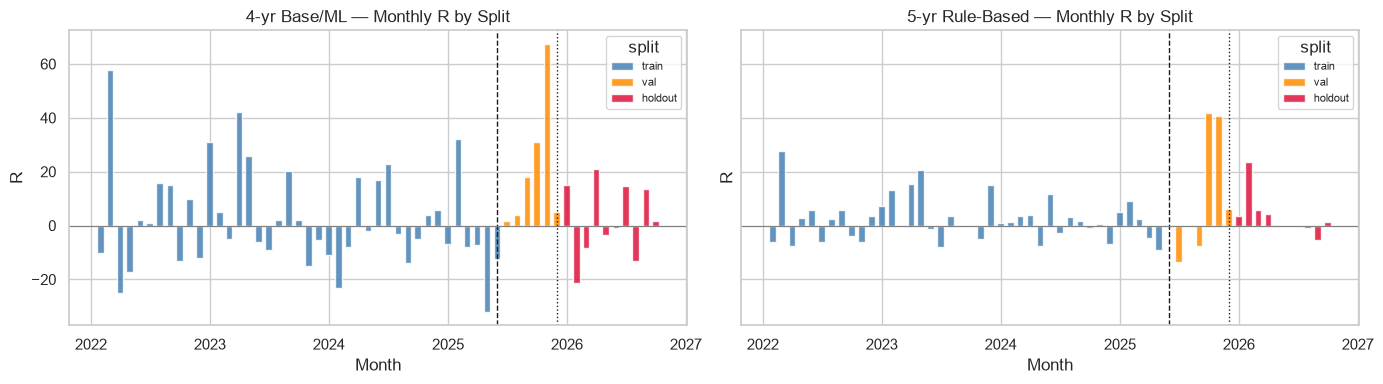

Saved C:\Users\user\Desktop\kairex-test-1\DATA\00_split_overview.png


In [13]:
colors = {'train': 'steelblue', 'val': 'darkorange', 'holdout': 'crimson'}

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (name, df) in zip(axes, [('4-yr Base/ML', df4), ('5-yr Rule-Based', df5)]):
    for split in ['train', 'val', 'holdout']:
        grp = df[df['split'] == split]
        if grp.empty:
            continue
        monthly = grp.set_index('open_time')['R'].resample('ME').sum()
        ax.bar(monthly.index, monthly.values, color=colors[split],
               alpha=0.85, label=split, width=20)
    ax.axvline(TRAIN_END, color='k', ls='--', lw=1)
    ax.axvline(VAL_END,   color='k', ls=':',  lw=1)
    ax.axhline(0, color='grey', lw=0.8)
    ax.set_title(f'{name} — Monthly R by Split')
    ax.set_xlabel('Month')
    ax.set_ylabel('R')
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.legend(title='split', fontsize=8)

plt.tight_layout()
plot_path = DATA_DIR / '00_split_overview.png'
plt.savefig(plot_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'Saved {plot_path}')

## 7. Missing-Value & Zero-Variance Audit
Missing values are reported per feature, and columns that carry **no information** are dropped from the list handed to the ML notebooks:

* all-NaN in either export (e.g. `dist_opp_zone_R` is 100% NaN in the rule-based file),
* single-valued in the 4-year training export (`planned_rr`, `server_gmt_offset_h`, `streak_mode`, `risk_pct_used`).

A column that is constant in the 4-year file but varies in the 5-year file cannot be learned from the training data, so it is dropped as well.

In [14]:
for name, df in (('4-yr', df4), ('5-yr', df5)):
    miss = df[FEATURE_COLS].isna().mean().mul(100).sort_values(ascending=False)
    high = miss[miss > 5]
    all_nan = [c for c in FEATURE_COLS if df[c].isna().all()]
    single  = [c for c in FEATURE_COLS if df[c].nunique(dropna=True) <= 1]
    print(f'[{name}] features with >5% missing ({len(high)}):')
    print(high.round(1).to_string() if len(high) else '  none')
    print(f'[{name}] all-NaN features       : {all_nan or "none"}')
    print(f'[{name}] single-valued features : {single or "none"}')
    print()

DROP_FEATURES = sorted({
    c for c in FEATURE_COLS
    if df4[c].isna().all() or df5[c].isna().all() or df4[c].nunique(dropna=True) <= 1
})
USABLE_FEATURES = [c for c in FEATURE_COLS if c not in DROP_FEATURES]

print(f'Dropped (zero information): {DROP_FEATURES}')
print(f'Usable feature columns    : {len(USABLE_FEATURES)} of {len(FEATURE_COLS)}')

[4-yr] features with >5% missing (1):
dist_opp_zone_R    24.2
[4-yr] all-NaN features       : none
[4-yr] single-valued features : ['planned_rr', 'server_gmt_offset_h', 'streak_mode', 'risk_pct_used']

[5-yr] features with >5% missing (1):
dist_opp_zone_R    100.0
[5-yr] all-NaN features       : ['dist_opp_zone_R']
[5-yr] single-valued features : ['direction', 'dist_opp_zone_R', 'consec_dir_bars', 'server_gmt_offset_h', 'streak_mode', 'risk_pct_used']

Dropped (zero information): ['dist_opp_zone_R', 'planned_rr', 'risk_pct_used', 'server_gmt_offset_h', 'streak_mode']
Usable feature columns    : 58 of 63


## 8. Save Processed Datasets
Written to `DATA/`: the two processed trade files (with `split`, `win`, `R`), the feature list consumed by notebooks 01–03, the split chart, and the completed reproducibility manifest (input + output SHA-256, row counts, feature lists, purged counts, outcome statistics).

In [15]:
out4 = DATA_DIR / 'base_ml_4yr_processed.csv'
out5 = DATA_DIR / 'rulebased_5yr_processed.csv'
df4.to_csv(out4, index=False, encoding='utf-8')
df5.to_csv(out5, index=False, encoding='utf-8')

# Feature list consumed by notebooks 01–03
feature_path = DATA_DIR / 'feature_cols.json'
with open(feature_path, 'w', encoding='utf-8') as f:
    json.dump(USABLE_FEATURES, f, indent=2)

# Complete the reproducibility manifest
manifest.update(
    n_rows={'4yr': int(len(df4)), '5yr': int(len(df5))},
    n_features={'entry_known': len(FEATURE_COLS), 'usable': len(USABLE_FEATURES)},
    feature_cols=USABLE_FEATURES,
    dropped_features=DROP_FEATURES,
    purged_straddlers={'4yr': purged4, '5yr': purged5},
    lag_check=lag_check,
    outcomes={'4yr': outcome_4, '5yr': outcome_5},
    outputs={p.name: file_sha256(p) for p in (out4, out5, plot_path)},
)
with open(manifest_path, 'w', encoding='utf-8') as mf:
    json.dump(manifest, mf, indent=2)

print('Saved:')
for p in (out4, out5, feature_path, plot_path, manifest_path):
    print(f'  {p.relative_to(DATA_DIR.parent)}')
print(f'\nTotal records → 4yr: {len(df4):,}  |  5yr: {len(df5):,}')
print(f'Features      → entry-known: {len(FEATURE_COLS)} | usable: {len(USABLE_FEATURES)}')
print(f"Split counts  → {df4['split'].value_counts().to_dict()}")

Saved:
  DATA\base_ml_4yr_processed.csv
  DATA\rulebased_5yr_processed.csv
  DATA\feature_cols.json
  DATA\00_split_overview.png
  DATA\run_manifest.json

Total records → 4yr: 3,040  |  5yr: 980
Features      → entry-known: 63 | usable: 58
Split counts  → {'train': 1995, 'holdout': 549, 'val': 496}
